# 03 · Handwriting and signature features on synthetic data

**Question.** Do S-Way's handwriting features and signature measures separate samples from the same (synthetic) writer from samples of different writers? Do the writer-identification texture features added in v1.1 — the **edge-hinge** distribution (Bulacu & Schomaker, 2007) and the **white-run** (spacing rhythm) distribution — add information beyond the 14 geometric features? How robust is everything to scanning degradations?

**Why synthetic?** Public writer-identification datasets (IAM, CVL, CEDAR, GPDS…) require registration and licence agreements that could not be accepted in this offline build. Synthetic writers are parameterised (slant, stroke width, size, spacing, baseline jitter, loopiness, ascender rate, line gap) and every sample adds natural within-writer variation. **These results validate the pipeline; they say nothing about accuracy on real people.**

**Protocol.** Writers are split into disjoint training and test groups (`GroupShuffleSplit`), so no writer appears in both. Scales, weights and thresholds are fitted on training writers only.

In [1]:
import sys, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.insert(0, '.')
from sway_research import *
RESULTS = DATA / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 90, 'font.family': 'monospace', 'axes.facecolor': '#EDE3CC', 'figure.facecolor': '#F4ECD9'})
pd.set_option('display.width', 140)

In [2]:
rng = random.Random(11)
N_WRITERS, N_SAMPLES = 36, 4
writers = [writer_params(rng) for _ in range(N_WRITERS)]
paths, wid = [], []
for w, p in enumerate(writers):
    for s in range(N_SAMPLES):
        path = WORK / f'hw_w{w:02d}_s{s}.png'
        draw_handwriting(path, p, seed=w * 100 + s)
        paths.append(path); wid.append(w)
feats = run_js([{'op': 'hwFeatures', 'png': str(p)} for p in paths], batch=40)
ok = [f.get('ok') for f in feats]
print(f'{sum(ok)}/{len(ok)} pages measured')
names = list(next(f for f in feats if f.get('ok'))['features'].keys())
F = pd.DataFrame([f['features'] for f in feats if f.get('ok')]); F['writer'] = [w for w, o in zip(wid, ok) if o]
HINGE = [np.array(f['histograms']['hinge']) for f in feats if f.get('ok')]
RUNS = [np.array(f['histograms']['whiteRuns']) for f in feats if f.get('ok')]
F.groupby('writer').mean().head(6).round(3)

144/144 pages measured


,slantDeg,slantSpread,strokeWidthRatio,wordGapRatio,charGapRatio,lineSpacingRatio,baselineVariation,componentAspect,ascenderRate,connectedness,inkDensity,marginRegularity,compactness,writingSize
writer,,,,,,,,,,,,,,
0,5.625,3.038,0.182,1.435,1.162,2.802,0.009,0.445,0.171,2.638,0.236,0.004,5.000,0.036
1,18.188,1.676,0.114,0.482,0.391,1.868,0.007,0.526,0.011,1.930,0.231,0.003,5.160,0.050
2,-26.812,1.048,0.135,1.330,1.086,2.522,0.009,0.442,0.100,2.390,0.203,0.003,5.620,0.037
3,-21.562,2.160,0.088,1.148,0.936,1.990,0.009,0.518,0.000,2.422,0.123,0.003,9.614,0.041
4,-15.000,1.222,0.102,0.978,0.782,2.043,0.008,0.575,0.000,1.820,0.162,0.004,6.126,0.042
5,30.188,4.465,0.216,0.903,0.715,1.602,0.011,0.541,0.006,1.900,0.290,0.004,3.646,0.033


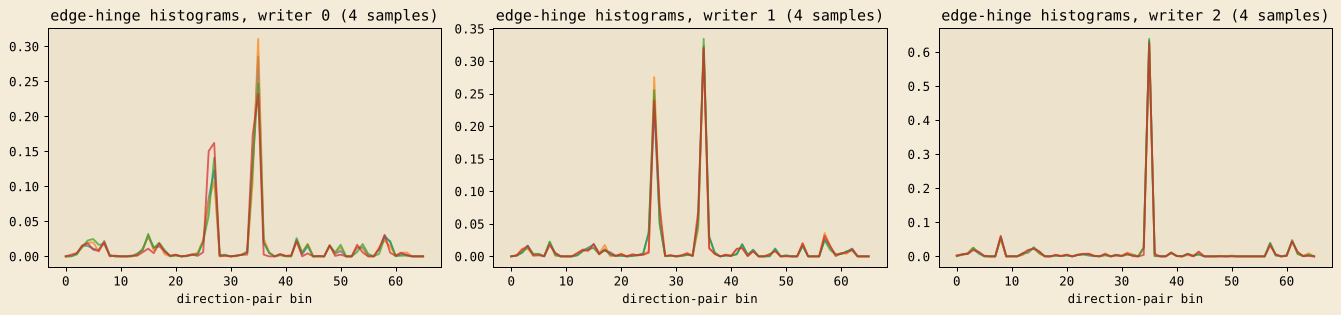

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, w in enumerate([0, 1, 2]):
    idx = [i for i, x in enumerate(F.writer) if x == w]
    for i in idx:
        ax[k].plot(HINGE[i], alpha=.7)
    ax[k].set_title(f'edge-hinge histograms, writer {w} ({len(idx)} samples)'); ax[k].set_xlabel('direction-pair bin')
plt.tight_layout(); plt.show()

In [4]:
from sklearn.model_selection import GroupShuffleSplit
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=3).split(F, groups=F.writer))
assert not set(F.writer.iloc[tr_idx]) & set(F.writer.iloc[te_idx]), 'writer leakage!'
train = F.iloc[tr_idx]
within = train.groupby('writer')[names].std().mean()
floor = train[names].std() * 0.15
scales = np.maximum(within * 1.5, floor).round(4)
pd.DataFrame({'within_writer_sd': within.round(4), 'scale_used': scales})

,within_writer_sd,scale_used
slantDeg,5.6297,8.4445
slantSpread,2.1052,3.1578
strokeWidthRatio,0.0138,0.0206
wordGapRatio,0.1052,0.1578
charGapRatio,0.0800,0.1200
lineSpacingRatio,0.1969,0.2953
baselineVariation,0.0022,0.0034
componentAspect,0.0276,0.0414
ascenderRate,0.0371,0.0556
connectedness,0.2262,0.3393


In [5]:
def pair_table(idx, max_neg=500, seed=0):
    rows = []
    for a_ in range(len(idx)):
        for b_ in range(a_ + 1, len(idx)):
            i, j = idx[a_], idx[b_]
            a, b = F.iloc[i], F.iloc[j]
            mz = float(np.mean(np.minimum(np.abs(a[names].values - b[names].values) / scales[names].values, 5)))
            rows.append(dict(same=int(a.writer == b.writer), meanZ=mz, d_hinge=1 - hist_sim(HINGE[i], HINGE[j]), d_runs=1 - hist_sim(RUNS[i], RUNS[j])))
    df = pd.DataFrame(rows)
    neg = df[df.same == 0].sample(min(max_neg, (df.same == 0).sum()), random_state=seed)
    return pd.concat([df[df.same == 1], neg])
P_tr, P_te = pair_table(list(tr_idx)), pair_table(list(te_idx))
auc = lambda d, col: roc_auc(-d[d.same == 1][col], -d[d.same == 0][col])
pd.DataFrame({'train AUC': {c: auc(P_tr, c) for c in ['meanZ', 'd_hinge', 'd_runs']}, 'test AUC': {c: auc(P_te, c) for c in ['meanZ', 'd_hinge', 'd_runs']}}).round(3)

,train AUC,test AUC
meanZ,0.966,0.984
d_hinge,0.964,0.990
d_runs,0.955,0.975


## Combining the evidence

A logistic regression on the **training** pairs learns how much each texture distance should count relative to the geometric meanZ. Its coefficients are converted into weights of a single, still-transparent distance

`distance = meanZ + w_hinge · (1 − hinge similarity) + w_runs · (1 − white-run similarity)`

which the app computes and the fusion thresholds act on. The test writers are only used for the final evaluation.

In [6]:
from sklearn.linear_model import LogisticRegression
X = P_tr[['meanZ', 'd_hinge', 'd_runs']].values; y = P_tr.same.values
lr = LogisticRegression(max_iter=5000, class_weight='balanced').fit(X, y)
c = lr.coef_[0]
w_h = max(0.0, c[1] / c[0]) if c[0] < 0 else 0.0
w_r = max(0.0, c[2] / c[0]) if c[0] < 0 else 0.0
w_h, w_r = round(min(w_h, 20), 3), round(min(w_r, 20), 3)
for P in (P_tr, P_te):
    P['distance'] = P.meanZ + w_h * P.d_hinge + w_r * P.d_runs
print(f'weights: hinge {w_h}, white-runs {w_r}')
abl = pd.DataFrame({'test AUC': {'14 geometric features (v1.0)': auc(P_te, 'meanZ'), 'edge-hinge only': auc(P_te, 'd_hinge'), 'combined distance (v1.1)': auc(P_te, 'distance')}})
e_old, _ = eer(-P_te[P_te.same == 1].meanZ, -P_te[P_te.same == 0].meanZ)
e_new, _ = eer(-P_te[P_te.same == 1].distance, -P_te[P_te.same == 0].distance)
abl['test EER'] = [e_old, np.nan, e_new]
abl.round(3)

weights: hinge 1.415, white-runs 0.543


,test AUC,test EER
14 geometric features (v1.0),0.984,0.074
edge-hinge only,0.990,NaN
combined distance (v1.1),0.995,0.036


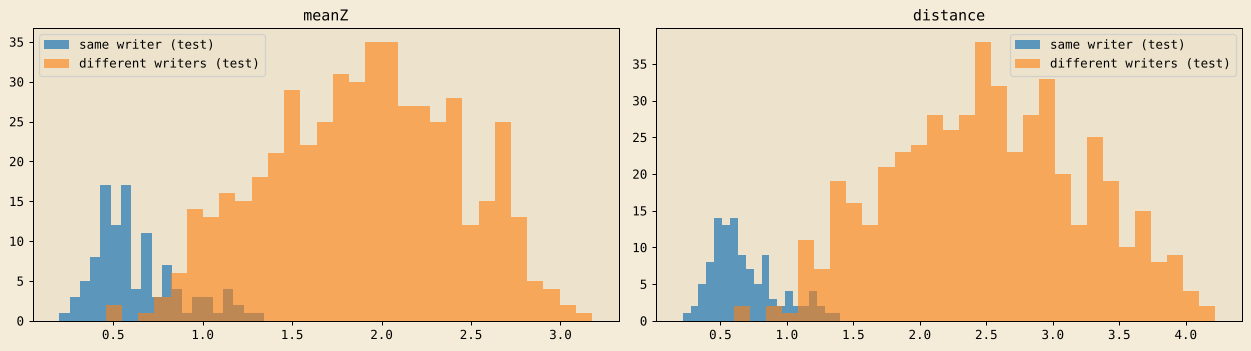

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col in zip(ax, ['meanZ', 'distance']):
    a.hist(P_te[P_te.same == 1][col], bins=20, alpha=.7, label='same writer (test)')
    a.hist(P_te[P_te.same == 0][col], bins=30, alpha=.6, label='different writers (test)')
    a.set_title(col); a.legend()
plt.tight_layout(); plt.show()

**Thresholds.** *High* similarity: the distance below which ≤ 5 % of different-writer **training** pairs fall; *Moderate*: ≤ 20 %. Then check on test writers.

In [8]:
d_tr_neg = P_tr[P_tr.same == 0].distance
high_t = float(np.quantile(d_tr_neg, 0.05)); mod_t = float(np.quantile(d_tr_neg, 0.20))
for nm, P in [('train', P_tr), ('test', P_te)]:
    s, d = P[P.same == 1].distance, P[P.same == 0].distance
    print(f'{nm}: High → {np.mean(s <= high_t):.0%} same-writer / {np.mean(d <= high_t):.0%} different-writer | Moderate+ → {np.mean(s <= mod_t):.0%} / {np.mean(d <= mod_t):.0%}')
print(f'thresholds on combined distance: High ≤ {high_t:.2f}, Moderate ≤ {mod_t:.2f}')

train: High → 94% same-writer / 5% different-writer | Moderate+ → 98% / 20%
test: High → 100% same-writer / 12% different-writer | Moderate+ → 100% / 31%
thresholds on combined distance: High ≤ 1.60, Moderate ≤ 2.13


## Robustness to scanning conditions

The second sample of each test writer is re-rendered with a degradation (blur, noise, 2.5° rotation, low resolution, heavy JPEG) and compared with that writer's clean first sample (genuine) and with other test writers (impostors).

In [9]:
test_writers = sorted(set(F.writer.iloc[te_idx]))
first = {w: next(i for i in te_idx if F.writer.iloc[i] == w) for w in test_writers}
def dist(fa, ha, ra, fb, hb, rb):
    mz = float(np.mean(np.minimum(np.abs(np.array([fa[n] for n in names]) - np.array([fb[n] for n in names])) / scales[names].values, 5)))
    return mz, mz + w_h * (1 - hist_sim(ha, hb)) + w_r * (1 - hist_sim(ra, rb))
rob = []
for kind in ['blur', 'noise', 'rotate', 'lowres', 'jpeg']:
    dpaths = []
    for w in test_writers:
        pth = WORK / f'hw_w{w:02d}_deg_{kind}.png'; draw_handwriting(pth, writers[w], seed=w * 100 + 1, degrade=kind); dpaths.append(pth)
    res = run_js([{'op': 'hwFeatures', 'png': str(p)} for p in dpaths], batch=40)
    same, diff = {'meanZ': [], 'distance': []}, {'meanZ': [], 'distance': []}
    for w, r in zip(test_writers, res):
        if not r.get('ok'): continue
        hd, rd = np.array(r['histograms']['hinge']), np.array(r['histograms']['whiteRuns'])
        for v in test_writers:
            i = first[v]
            mz, dd = dist(r['features'], hd, rd, F.iloc[i], HINGE[i], RUNS[i])
            tgt = same if v == w else diff
            tgt['meanZ'].append(mz); tgt['distance'].append(dd)
    rob.append(dict(degradation=kind, auc_v10=roc_auc(-np.array(same['meanZ']), -np.array(diff['meanZ'])), auc_v11=roc_auc(-np.array(same['distance']), -np.array(diff['distance']))))
pd.DataFrame(rob).round(3)

,degradation,auc_v10,auc_v11
0,blur,0.966,0.967
1,noise,0.987,0.994
2,rotate,0.987,0.994
3,lowres,0.977,0.981
4,jpeg,0.988,0.995


## Siamese networks — scope note

The specification asks to *explore* Siamese networks. A CNN Siamese model needs a real, licensed, writer-labelled dataset and GPU time; neither was available, so **no neural model is shipped**. The logistic combination above is the "learned similarity" S-Way actually uses: three interpretable distances, weighted by a model fitted with a writer-disjoint protocol. A Siamese model would replace the hand-crafted features with learned embeddings under the same protocol; `docs/MODEL_CARD.md` lists this as future work.

## Signatures

20 synthetic signers. Genuine samples vary naturally; **skilled forgeries** are drawn from the same base shape with distortion and extra tremor; **random forgeries** are other people's genuine signatures. Signers are split into disjoint halves for threshold fitting and testing.

In [10]:
rng = random.Random(5)
signers = [signature_base(rng) for _ in range(20)]
gen, sk = {}, {}
for i, b in enumerate(signers):
    gen[i] = []; sk[i] = []
    for k in range(4):
        p = WORK / f'sig_{i:02d}_g{k}.png'; draw_signature(p, b, seed=i * 50 + k, variation=1.4); gen[i].append(p)
    for k in range(2):
        p = WORK / f'sig_{i:02d}_f{k}.png'; draw_signature(p, b, seed=i * 50 + 30 + k, variation=2.6, distort=0.07); sk[i].append(p)
tasks, meta = [], []
for i in range(20):
    for a in range(4):
        for b_ in range(a + 1, 4):
            tasks.append({'op': 'signature', 'a': str(gen[i][a]), 'b': str(gen[i][b_])}); meta.append((i, 'genuine'))
    for a in range(2):
        for f in sk[i]:
            tasks.append({'op': 'signature', 'a': str(gen[i][a]), 'b': str(f)}); meta.append((i, 'skilled forgery'))
    for j in rng.sample([x for x in range(20) if x != i], 3):
        tasks.append({'op': 'signature', 'a': str(gen[i][0]), 'b': str(gen[j][0])}); meta.append((i, 'random forgery'))
sres = run_js(tasks, batch=60)
S = pd.DataFrame([dict(signer=m[0], kind=m[1], **r['metrics']) for m, r in zip(meta, sres) if r.get('ok')])
S.groupby('kind')[['tolerantOverlap', 'chamferDistancePx', 'ssim']].median().round(3)

,tolerantOverlap,chamferDistancePx,ssim
kind,,,
genuine,0.682,0.845,0.930
random forgery,0.140,12.280,0.778
skilled forgery,0.468,2.145,0.876


In [11]:
tr = S[S.signer < 10]; te = S[S.signer >= 10]
g_te, r_te, s_te_ = te[te.kind == 'genuine'], te[te.kind == 'random forgery'], te[te.kind == 'skilled forgery']
print('test AUC genuine vs random forgery (overlap):', round(roc_auc(g_te.tolerantOverlap, r_te.tolerantOverlap), 3))
print('test AUC genuine vs skilled forgery (overlap):', round(roc_auc(g_te.tolerantOverlap, s_te_.tolerantOverlap), 3))
rnd_tr = tr[tr.kind == 'random forgery']
hi_ov = float(np.quantile(rnd_tr.tolerantOverlap, 0.95)); hi_ch = float(np.quantile(rnd_tr.chamferDistancePx, 0.05))
mo_ov = float(np.quantile(rnd_tr.tolerantOverlap, 0.80)); mo_ch = float(np.quantile(rnd_tr.chamferDistancePx, 0.20))
print(f'High: overlap ≥ {hi_ov:.2f} and chamfer ≤ {hi_ch:.1f}px | Moderate: overlap ≥ {mo_ov:.2f} or chamfer ≤ {mo_ch:.1f}px')
for k, g in te.groupby('kind'):
    print(f'  test {k:16s}: labelled High {((g.tolerantOverlap >= hi_ov) & (g.chamferDistancePx <= hi_ch)).mean():.0%}')

test AUC genuine vs random forgery (overlap): 1.0
test AUC genuine vs skilled forgery (overlap): 0.947
High: overlap ≥ 0.28 and chamfer ≤ 5.8px | Moderate: overlap ≥ 0.22 or chamfer ≤ 8.9px
  test genuine         : labelled High 100%
  test random forgery  : labelled High 0%
  test skilled forgery : labelled High 100%


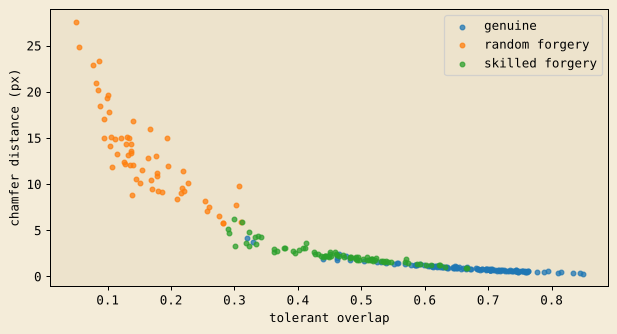

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
for k, g in S.groupby('kind'):
    ax.scatter(g.tolerantOverlap, g.chamferDistancePx, s=14, label=k, alpha=.75)
ax.set_xlabel('tolerant overlap'); ax.set_ylabel('chamfer distance (px)'); ax.legend(); plt.show()

**Reading.** Skilled forgeries overlap with genuine pairs far more than random forgeries do — exactly why S-Way never labels a signature authentic or forged from visual similarity alone.

In [13]:
out = {'handwriting_scales': {**{k: float(v) for k, v in scales.items()}, 'hingeWeight': w_h, 'whiteRunWeight': w_r},
       'handwriting_fusion': {'highMeanZ': round(high_t, 3), 'modMeanZ': round(mod_t, 3)},
       'signature_fusion': {'highOverlap': round(hi_ov, 3), 'highChamfer': round(hi_ch, 2), 'modOverlap': round(mo_ov, 3), 'modChamfer': round(mo_ch, 2)},
       'metrics': {'handwriting_test_auc_v10': auc(P_te, 'meanZ'), 'handwriting_test_auc': auc(P_te, 'distance'), 'handwriting_test_eer_v10': e_old, 'handwriting_test_eer': e_new,
                   'hinge_only_test_auc': auc(P_te, 'd_hinge'), 'robustness': rob,
                   'signature_auc_random': roc_auc(g_te.tolerantOverlap, r_te.tolerantOverlap), 'signature_auc_skilled': roc_auc(g_te.tolerantOverlap, s_te_.tolerantOverlap)}}
(RESULTS / 'visual.json').write_text(json.dumps(out, indent=2, default=float)); out['handwriting_fusion'], out['handwriting_scales']['hingeWeight'], out['signature_fusion']

({'highMeanZ': 1.601, 'modMeanZ': 2.127},
 np.float64(1.415),
 {'highOverlap': 0.282,
  'highChamfer': 5.83,
  'modOverlap': 0.219,
  'modChamfer': 8.92})